<a href="https://colab.research.google.com/github/endy24ti-commits/Probabilitas_Statistika_Endy3TID/blob/main/Hasil_Akhir_Dari_Data_Kuesioner_3_TID_Endy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pingouin factor_analyzer -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.


In [1]:
!pip install --upgrade numpy scipy pingouin factor_analyzer

In [2]:
import re
import pandas as pd, numpy as np, pingouin as pg
from scipy import stats
from factor_analyzer import FactorAnalyzer, calculate_kmo, calculate_bartlett_sphericity

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [3]:
from google.colab import files
up = files.upload()
nama_file = list(up.keys())[0]
print("File terbaca:", nama_file)

Saving KUISIONER LATIHAN MK STATISTIKA PROBABILITAS (Responses).xlsx to KUISIONER LATIHAN MK STATISTIKA PROBABILITAS (Responses).xlsx
File terbaca: KUISIONER LATIHAN MK STATISTIKA PROBABILITAS (Responses).xlsx


In [4]:
JUMLAH_KOLOM_DEMOGRAFI = 5
df = pd.read_excel(nama_file)
butir = df.iloc[:, JUMLAH_KOLOM_DEMOGRAFI:]
print("Jumlah responden :", len(df))
print("Jumlah butir :", butir.shape[1])
print("Data kosong :", int(butir.isna().sum().sum()))

Jumlah responden : 38
Jumlah butir : 28
Data kosong : 0


In [5]:
skala = {
    "Sangat Tidak Setuju (STS)": 1,
    "Tidak Setuju (TS)": 2,
    "Netral (N)": 3,
    "Setuju (S)": 4,
    "Sangat Setuju (SS)": 5,
    }

num = butir.replace(skala).apply(pd.to_numeric, errors="coerce")

# Harus 0. Jika lebih dari 0, ada jawaban yang tidak terbaca.
print("Sel yang gagal dikonversi:", int(num.isna().sum().sum()))
num.head()

Sel yang gagal dikonversi: 38


,Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan platform AI hampir setiap kali mendapatkan tugas akademik.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari solusi atas permasalahan atau soal perkuliahan.],Penggunaan AI pada tugas atau projek kuliah [Saya menggunakan AI untuk mencari ide atau inspirasi dalam mengerjakan tugas./projek],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kesulitan memulai mengerjakan tugas tanpa bantuan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya merasa kurang yakin dengan hasil tugas apabila tidak menggunakan AI.],Penggunaan AI pada tugas atau projek kuliah [Saya percaya bahwa AI dapat memberikan informasi yang membantu penyelesaian tugas.],Penggunaan AI pada tugas atau projek kuliah [Saya memanfaatkan AI untuk menemukan ide alternatif ketika mengembangkan topik tugas atau projek perkuliahan.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya merasa perlu menggunakan AI setiap kali mendapatkan tugas atau proyek kuliah.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [aya merasa kesulitan menyelesaikan tugas kuliah apabila tidak menggunakan bantuan AI.],Aspek Psikologis penggunaan AI pada tugas atau projek kuliah [Saya cenderung mengikuti saran atau jawaban AI tanpa banyak mempertimbangkan alternatif lainnya (Non-AI).],...,Kebiasaan penggunaan teknologi digital [Saya tidak mengkhawatirkan hasil yang diberikan AI],Kebiasaan penggunaan teknologi digital [Saya jarang memeriksa kembali hasil dari AI karena sudah percaya terhadap ketepatan jawabannya.],Prokrastinasi akademik. [Saya cenderung menunggu hingga mendekati deadline untuk mulai mengerjakan tugas.],Prokrastinasi akademik. [Saya sering menunda pengerjaan tugas karena merasa dapat dikerjakan dengan mudah dan cepat dengan menggunakan AI],Prokrastinasi akademik. [Saya sering menyelesaikan tugas kuliah dalam waktu yang sangat dekat dengan batas pengumpulan.],Prokrastinasi akademik. [Saya sering mengerjakan beberapa tugas sekaligus karena sebelumnya menunda pengerjaannya.],Rsspon emosional [Saya merasa tertekan ketika harus menyelesaikan tugas dalam waktu singkat akibat menunda pengerjaannya.],Rsspon emosional [Saya merasa panik ketika beberapa tugas yang saya tunda memiliki batas waktu pengumpulan yang berdekatan.],Rsspon emosional [Saya merasa kurang puas terhadap hasil tugas yang dikerjakan karena terburu-buru mendekati deadline.],Rsspon emosional [Saya merasa menyesal karena hasil tugas mungkin bisa lebih baik apabila dikerjakan lebih awal.]
0,5,5,5,5,4,4,5,5,5,1,...,4,4,5,1,5,4,1,1,1,5
1,4,4,5,4,3,4,4,3,1,1,...,4,2,2,2,2,4,5,5,5,5
2,2,4,2,4,4,4,2,4,4,4,...,4,2,4,4,2,2,2,4,4,5
3,4,5,5,4,5,5,5,4,4,4,...,2,1,1,1,1,1,5,5,5,5
4,5,4,5,5,4,4,3,3,1,3,...,4,1,5,5,4,5,5,4,4,5


In [25]:
dimensi = {}
for kolom in butir.columns:
  hasil = re.match(r"^(.*?)\s\[", kolom)
  if hasil:
    nama = hasil.group(1).strip()
    dimensi.setdefault(nama, []).append(kolom)

# Pembagian Topic
pembagian_topic = {
    "Penggunaan AI pada tugas atau projek kuliah": "Topic 1",
    "Aspek Psikologis penggunaan AI pada tugas atau projek kuliah": "Topic 1",
    "Kebiasaan penggunaan teknologi digital": "Topic 2",
    "Prokrastinasi akademik.": "Topic 2",
    "Respon emosional": "Topic 2"
    }

for nama, daftar in dimensi.items():
  topic = pembagian_topic.get(nama, "Belum ditentukan")
  print(f"\n{topic} - {nama}: {len(daftar)} butir")


Topic 1 - Penggunaan AI pada tugas atau projek kuliah: 7 butir

Topic 1 - Aspek Psikologis penggunaan AI pada tugas atau projek kuliah: 6 butir

Topic 2 - Kebiasaan penggunaan teknologi digital: 6 butir

Topic 2 - Prokrastinasi akademik.: 4 butir

Belum ditentukan - Rsspon emosional: 4 butir


In [24]:
n = len(num)
t = stats.t.ppf(0.975, n - 2)
r_tabel = t / np.sqrt((n - 2) + t**2)
print(f"n = {n} | r tabel (a=0,05; df={n-2}) = {r_tabel:.3f}")

hasil_validitas = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    total = x.sum(axis=1)
    for i, kolom in enumerate(daftar, 1):
        r, p = stats.pearsonr(x[kolom], total)
        r_koreksi, _ = stats.pearsonr(x[kolom], total - x[kolom])
        hasil_validitas.append({
            "Dimensi": nama,
            "Butir": f"B{i}",
            "r hitung": round(r, 3),
            "Corrected r": round(r_koreksi, 3),
            "p-value": round(p, 4),
            "Keterangan": "Valid" if r > r_tabel else "Tidak valid",
        })

tabel_validitas = pd.DataFrame(hasil_validitas)
tabel_validitas

n = 38 | r tabel (a=0,05; df=36) = 0.320


,Dimensi,Butir,r hitung,Corrected r,p-value,Keterangan
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.723,0.547,0.0000,Valid
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.393,0.260,0.0145,Valid
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.428,0.257,0.0074,Valid
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.470,0.240,0.0029,Valid
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.703,0.523,0.0000,Valid
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.739,0.627,0.0000,Valid
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.738,0.550,0.0000,Valid
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.651,0.516,0.0000,Valid
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.750,0.567,0.0000,Valid
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.643,0.430,0.0000,Valid


In [13]:
def cronbach_alpha(x):
    k = x.shape[1]
    return k / (k - 1) * (1 - x.var(ddof=1).sum() / x.sum(axis=1).var(ddof=1))

def kategori(a):
    return ("Sangat baik" if a >= 0.90 else "Baik" if a >= 0.80
            else "Reliabel" if a >= 0.70 else "Tidak reliabel")

hasil_reliabilitas = []
alpha_dihapus = []
for nama, daftar in dimensi.items():
    x = num[daftar]
    a = cronbach_alpha(x)
    hasil_reliabilitas.append({"Dimensi": nama, "Jumlah butir": len(daftar),
                               "Cronbach's alpha": round(a, 3), "Kategori": kategori(a)})
    for i, kolom in enumerate(daftar, 1):
        if len(daftar) > 2:
            alpha_dihapus.append({"Dimensi": nama, "Butir": f"B{i}",
                                  "Alpha jika dihapus": round(cronbach_alpha(x.drop(columns=kolom)), 3)})

tabel_reliabilitas = pd.DataFrame(hasil_reliabilitas)
tabel_alpha_dihapus = pd.DataFrame(alpha_dihapus)
display(tabel_reliabilitas)
display(tabel_alpha_dihapus)

,Dimensi,Jumlah butir,Cronbach's alpha,Kategori
0,Penggunaan AI pada tugas atau projek kuliah,7,0.713,Reliabel
1,Aspek Psikologis penggunaan AI pada tugas atau...,6,0.728,Reliabel
2,Kebiasaan penggunaan teknologi digital,6,0.754,Reliabel
3,Prokrastinasi akademik.,4,0.817,Baik
4,Rsspon emosional,4,0.813,Baik


,Dimensi,Butir,Alpha jika dihapus
0,Penggunaan AI pada tugas atau projek kuliah,B1,0.645
1,Penggunaan AI pada tugas atau projek kuliah,B2,0.714
2,Penggunaan AI pada tugas atau projek kuliah,B3,0.715
3,Penggunaan AI pada tugas atau projek kuliah,B4,0.728
4,Penggunaan AI pada tugas atau projek kuliah,B5,0.653
5,Penggunaan AI pada tugas atau projek kuliah,B6,0.639
6,Penggunaan AI pada tugas atau projek kuliah,B7,0.644
7,Aspek Psikologis penggunaan AI pada tugas atau...,B1,0.683
8,Aspek Psikologis penggunaan AI pada tugas atau...,B2,0.656
9,Aspek Psikologis penggunaan AI pada tugas atau...,B3,0.701


In [14]:
gabung = tabel_validitas.merge(tabel_alpha_dihapus, on=["Dimensi", "Butir"], how="left")

with pd.ExcelWriter("hasil_uji_validitas_reliabilitas.xlsx") as w:
  gabung.to_excel(w, sheet_name="Validitas", index=False)
  tabel_reliabilitas.to_excel(w, sheet_name="Reliabilitas", index=False)

files.download("hasil_uji_validitas_reliabilitas.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **KODE MENAMPILKAN DISTRIBUSI PADA DATA**

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Mengambil hanya 27 butir yang termasuk dalam lima dimensi
kolom_dimensi = [kolom for daftar in dimensi.values() for kolom in daftar]
data_dimensi = num[kolom_dimensi].copy()

print("Jumlah responden:", len(data_dimensi))
print("Jumlah butir Likert:", data_dimensi.shape[1])
print("Jumlah data kosong:", data_dimensi.isna().sum().sum())

# Menghitung rata-rata skor setiap dimensi untuk setiap responden
skor_dimensi = pd.DataFrame()

for nama, daftar in dimensi.items():
    skor_dimensi[nama] = data_dimensi[daftar].mean(axis=1)

display(skor_dimensi.head())

Jumlah responden: 38
Jumlah butir Likert: 27
Jumlah data kosong: 0


,Penggunaan AI pada tugas atau projek kuliah,Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,Kebiasaan penggunaan teknologi digital,Prokrastinasi akademik.,Rsspon emosional
0,4.714286,4.333333,3.500000,3.75,2.00
1,4.000000,1.833333,2.500000,2.50,5.00
2,3.142857,4.166667,3.833333,3.00,3.75
3,4.714286,4.333333,1.666667,1.00,5.00
4,4.285714,3.000000,3.333333,4.75,4.50


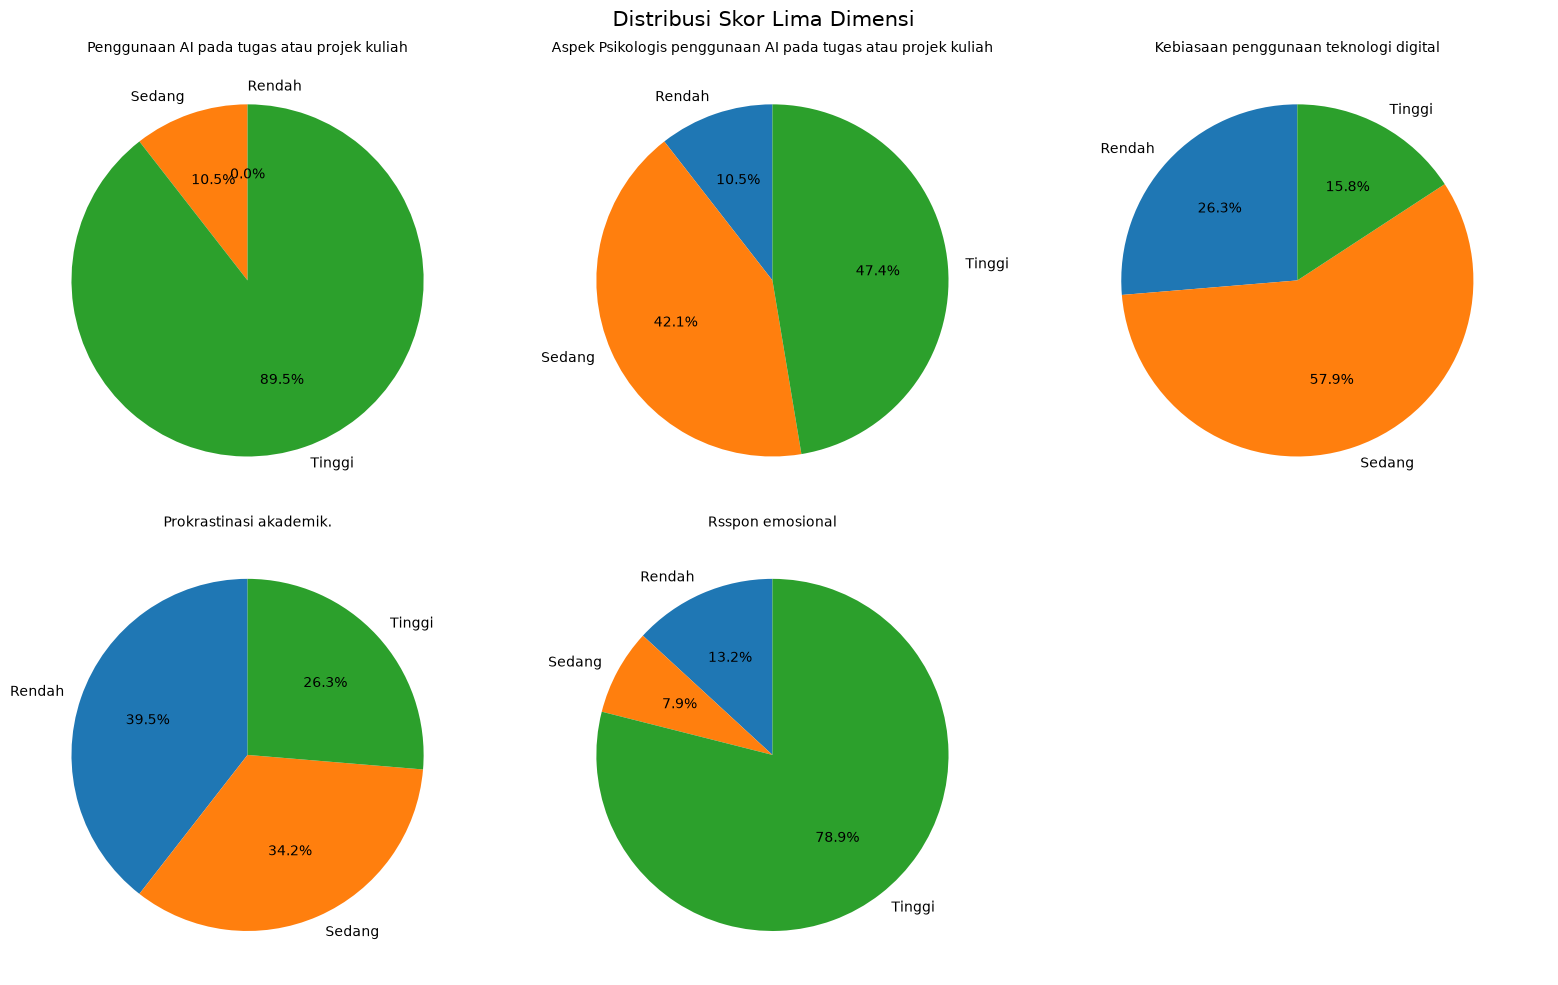

Jumlah responden setiap kategori:


,Rendah,Sedang,Tinggi,Total
Penggunaan AI pada tugas atau projek kuliah,0,4,34,38
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,4,16,18,38
Kebiasaan penggunaan teknologi digital,10,22,6,38
Prokrastinasi akademik.,15,13,10,38
Rsspon emosional,5,3,30,38


Persentase distribusi setiap dimensi:


,Rendah,Sedang,Tinggi
Penggunaan AI pada tugas atau projek kuliah,0.00,10.53,89.47
Aspek Psikologis penggunaan AI pada tugas atau projek kuliah,10.53,42.11,47.37
Kebiasaan penggunaan teknologi digital,26.32,57.89,15.79
Prokrastinasi akademik.,39.47,34.21,26.32
Rsspon emosional,13.16,7.89,78.95


In [17]:
# Mengelompokkan skor menjadi tiga kategori
batas = [0.99, 2.33, 3.67, 5.00]
kategori = ["Rendah", "Sedang", "Tinggi"]

distribusi = {}

for kolom in skor_dimensi.columns:
    kategori_skor = pd.cut(
        skor_dimensi[kolom],
        bins=batas,
        labels=kategori,
        include_lowest=True
    )

    distribusi[kolom] = kategori_skor.value_counts().reindex(
        kategori, fill_value=0
    )

# Menampilkan lima pie chart
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, kolom in enumerate(skor_dimensi.columns):
    axes[i].pie(
        distribusi[kolom],
        labels=kategori,
        autopct="%1.1f%%",
        startangle=90
    )
    axes[i].set_title(kolom, fontsize=10)

axes[5].axis("off")
plt.suptitle("Distribusi Skor Lima Dimensi", fontsize=15)
plt.tight_layout()
plt.show()

# Tabel jumlah dan persentase
tabel_distribusi = pd.DataFrame(distribusi).T
tabel_distribusi["Total"] = tabel_distribusi.sum(axis=1)

tabel_persentase = (
    tabel_distribusi[kategori]
    .div(tabel_distribusi["Total"], axis=0) * 100
).round(2)

print("Jumlah responden setiap kategori:")
display(tabel_distribusi)

print("Persentase distribusi setiap dimensi:")
display(tabel_persentase)

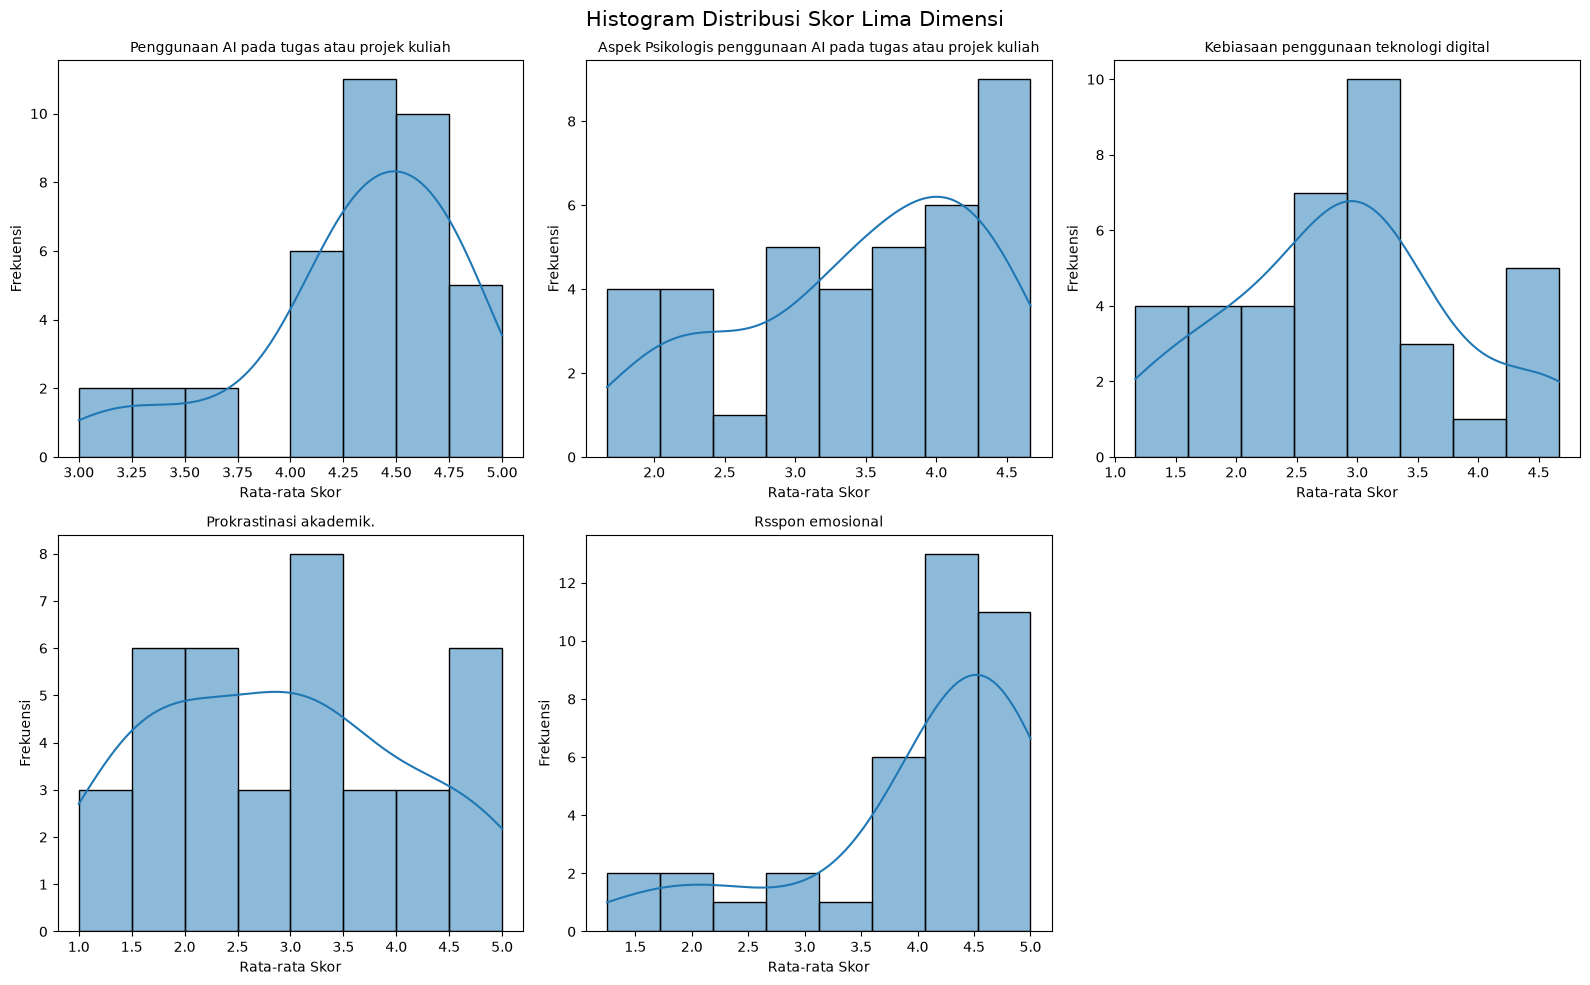

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, kolom in enumerate(skor_dimensi.columns):
    sns.histplot(
        skor_dimensi[kolom],
        bins=8,
        kde=True,
        ax=axes[i]
    )
    axes[i].set_title(kolom, fontsize=10)
    axes[i].set_xlabel("Rata-rata Skor")
    axes[i].set_ylabel("Frekuensi")

axes[5].axis("off")
plt.suptitle("Histogram Distribusi Skor Lima Dimensi", fontsize=15)
plt.tight_layout()
plt.show()

In [19]:
hasil_statistik = []

for kolom in skor_dimensi.columns:
    hasil_statistik.append({
        "Dimensi": kolom,
        "Mean": skor_dimensi[kolom].mean(),
        "Median": skor_dimensi[kolom].median(),
        "Standar Deviasi": skor_dimensi[kolom].std(),
        "Minimum": skor_dimensi[kolom].min(),
        "Maksimum": skor_dimensi[kolom].max(),
        "Skewness": skor_dimensi[kolom].skew(),
        "Kurtosis": skor_dimensi[kolom].kurt()
    })

tabel_statistik = pd.DataFrame(hasil_statistik).round(3)
display(tabel_statistik)

,Dimensi,Mean,Median,Standar Deviasi,Minimum,Maksimum,Skewness,Kurtosis
0,Penggunaan AI pada tugas atau projek kuliah,4.312,4.429,0.491,3.000,5.000,-1.128,0.875
1,Aspek Psikologis penggunaan AI pada tugas atau...,3.461,3.667,0.872,1.667,4.667,-0.559,-0.855
2,Kebiasaan penggunaan teknologi digital,2.882,2.917,0.959,1.167,4.667,0.132,-0.432
3,Prokrastinasi akademik.,2.882,3.000,1.187,1.000,5.000,0.205,-1.010
4,Rsspon emosional,4.020,4.500,1.029,1.250,5.000,-1.412,1.093


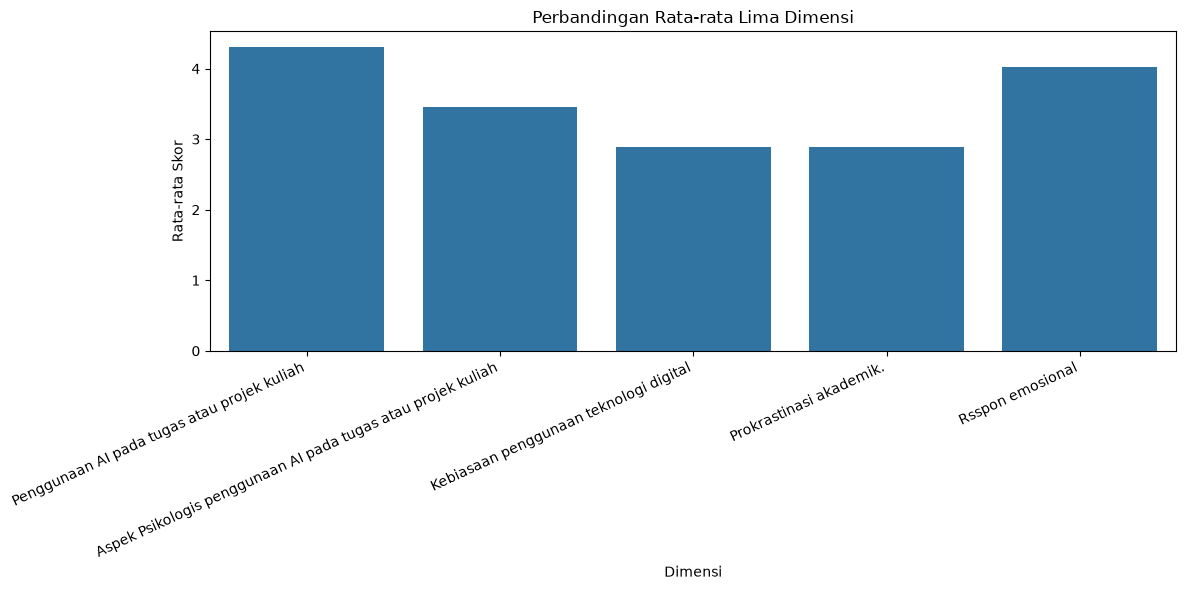

,Dimensi,Mean,Median,Standar Deviasi,Minimum,Maksimum
0,Penggunaan AI pada tugas atau projek kuliah,4.312,4.429,0.491,3.000,5.000
1,Aspek Psikologis penggunaan AI pada tugas atau...,3.461,3.667,0.872,1.667,4.667
2,Kebiasaan penggunaan teknologi digital,2.882,2.917,0.959,1.167,4.667
3,Prokrastinasi akademik.,2.882,3.000,1.187,1.000,5.000
4,Rsspon emosional,4.020,4.500,1.029,1.250,5.000


In [21]:
# Perbandingan rata-rata setiap dimensi
plt.figure(figsize=(12, 6))

sns.barplot(
    x=tabel_statistik["Dimensi"],
    y=tabel_statistik["Mean"]
)

plt.title("Perbandingan Rata-rata Lima Dimensi")
plt.xlabel("Dimensi")
plt.ylabel("Rata-rata Skor")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

# Tabel perbandingan parameter
display(
    tabel_statistik[
        ["Dimensi", "Mean", "Median", "Standar Deviasi",
         "Minimum", "Maksimum"]
    ]
)

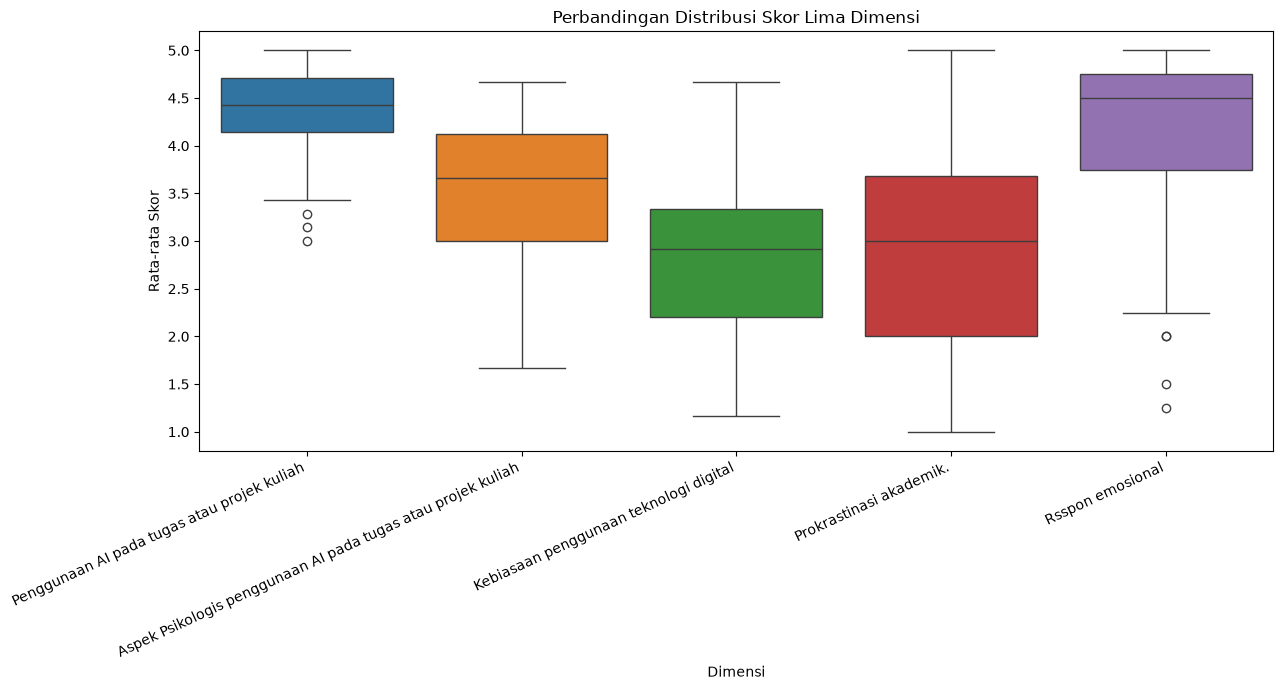

In [22]:
plt.figure(figsize=(13, 7))

sns.boxplot(data=skor_dimensi)

plt.title("Perbandingan Distribusi Skor Lima Dimensi")
plt.xlabel("Dimensi")
plt.ylabel("Rata-rata Skor")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()